In [7]:
# Step 1: importing the tools we need
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

# Step 2: loading the dataset
digits = load_digits()
X = digits.data
Y = digits.target

# Step 3: splitting the data
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size = 0.2,
    random_state = 42,
    stratify = Y
)

# Step 4: reshaping for the CNN to fit what we are looking for
X_train_cnn = X_train.reshape(-1, 8, 8, 1) / 16.0
X_test_cnn = X_test.reshape(-1, 8, 8, 1) / 16.0

print("Training shape:", X_train_cnn.shape)
print("Testing shape:", X_test_cnn.shape)

Training shape: (1437, 8, 8, 1)
Testing shape: (360, 8, 8, 1)


In [8]:
# Step 5: building the CNN, layer by layer
model = keras.Sequential([
    layers.Input(shape = (8, 8, 1)),                                     # one 8x8 grayscale image
    layers.Conv2D(32, (3, 3), activation = "relu", padding = "same"),    # 32 pattern detectors
    layers.MaxPooling2D((2, 2)),                                         # shrink 8x8 down to 4x4
    layers.Conv2D(64, (3, 3), activation = "relu", padding = "same"),    # 64 detectors for bigger shapes
    layers.Flatten(),                                                    # turn the grid into one long list
    layers.Dense(64, activation = "relu"),                               # combine the patterns
    layers.Dense(10, activation = "softmax")                             # 10 outputs: one per digit
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,066 (332.29 KB)

 Trainable params: 85,066 (332.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Step 6: choosing how the CNN learns
model.compile(
    optimizer = "adam",                           # the method for adjusting the parameters
    loss = "sparse_categorical_crossentropy",     # measures how wrong the guesses are
    metrics = ["accuracy"]
)

# Step 7: training
history = model.fit(
    X_train_cnn, Y_train,
    epochs = 30,              # go through all training images 30 times
    batch_size = 32,          # update the parameters after every 32 images
    validation_split = 0.1,   # hold back 10% of the training images to check progress
    verbose = 1
)

Epoch 1/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5282 - loss: 1.7342 - val_accuracy: 0.8333 - val_loss: 0.8598
Epoch 2/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8871 - loss: 0.4806 - val_accuracy: 0.9444 - val_loss: 0.2715
Epoch 3/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9389 - loss: 0.2185 - val_accuracy: 0.9583 - val_loss: 0.1653
Epoch 4/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9598 - loss: 0.1382 - val_accuracy: 0.9583 - val_loss: 0.1303
Epoch 5/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9753 - loss: 0.1008 - val_accuracy: 0.9583 - val_loss: 0.1028
Epoch 6/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9853 - loss: 0.0732 - val_accuracy: 0.9861 - val_loss: 0.0818
Epoch 7/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9923 - loss: 0.0495 - val_accuracy: 0.9792 - val_loss: 0.0703
Epoch 8/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9946 - loss: 0.0367 - val_accuracy: 0.9792 - val_los

CNN test accuracy: 97.50%
Number of incorrect predictions: 9


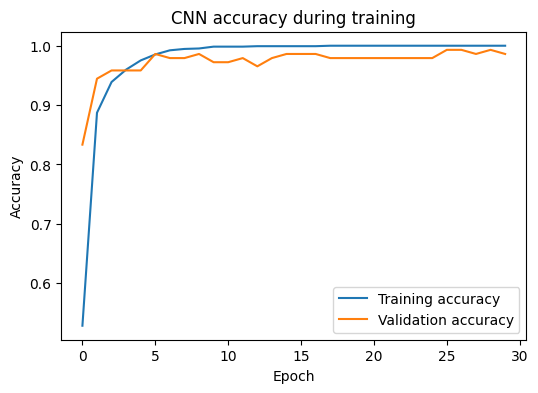

In [10]:
import matplotlib.pyplot as plt

# Step 8: the final exam on the 360 test images
test_loss, test_accuracy = model.evaluate(X_test_cnn, Y_test, verbose = 0)
Y_pred_cnn = model.predict(X_test_cnn, verbose = 0).argmax(axis = 1)  # pick the digit with the highest score

print(f"CNN test accuracy: {test_accuracy:.2%}")
print("Number of incorrect predictions:", (Y_test != Y_pred_cnn).sum())

# Step 9: training curve - accuracy for every epoch
plt.figure(figsize = (6, 4))
plt.plot(history.history["accuracy"], label = "Training accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation accuracy")
plt.title("CNN accuracy during training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig("cnn_training_curve.png")
plt.show()

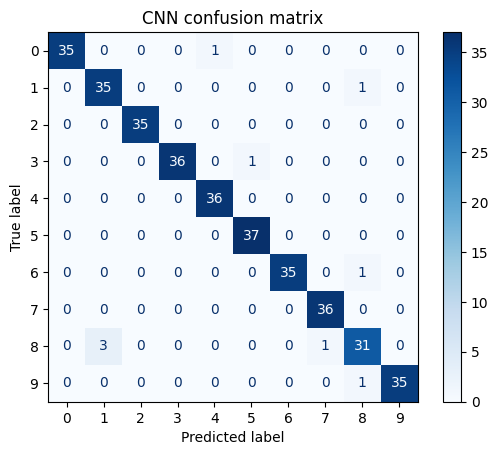

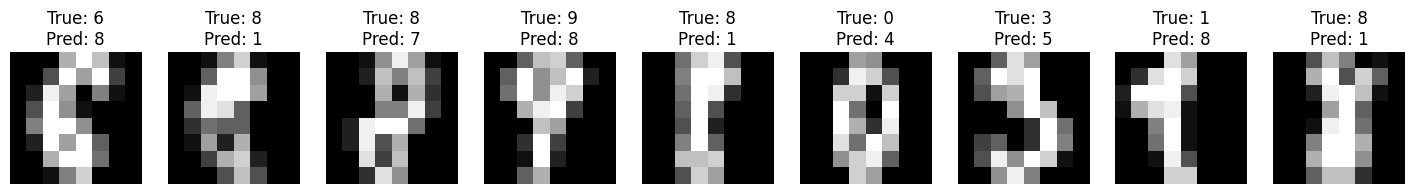

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

# Step 10: CNN confusion matrix
ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred_cnn, cmap = "Blues")
plt.title("CNN confusion matrix")
plt.savefig("cnn_confusion_matrix.png")
plt.show()

# Step 11: the images the CNN got wrong
wrong = (Y_test != Y_pred_cnn).nonzero()[0]

plt.figure(figsize = (2 * len(wrong), 2.5))
for i, index in enumerate(wrong):
    plt.subplot(1, len(wrong), i + 1)
    plt.imshow(X_test[index].reshape(8, 8), cmap = "gray")
    plt.title(f"True: {Y_test[index]}\nPred: {Y_pred_cnn[index]}")
    plt.axis("off")
plt.savefig("cnn_misclassified.png")
plt.show()

In [12]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# Step 12: re-running KNN and SVM on the same split (flat 64-number rows, like before)
knn = KNeighborsClassifier(n_neighbors = 3).fit(X_train, Y_train)
Y_pred_knn = knn.predict(X_test)

svm = SVC(C = 10, gamma = 0.001).fit(X_train, Y_train)  # the best settings found in 05_svm.py
Y_pred_svm = svm.predict(X_test)

# Step 13: one results table for all three models
predictions = {
    "KNN (k=3)": Y_pred_knn,
    "SVM": Y_pred_svm,
    "CNN": Y_pred_cnn
}

for name, pred in predictions.items():
    accuracy = accuracy_score(Y_test, pred)
    f1 = f1_score(Y_test, pred, average = "macro")
    mistakes = (Y_test != pred).sum()
    print(f"{name:10s} accuracy: {accuracy:.2%}   macro F1: {f1:.3f}   mistakes: {mistakes}")

KNN (k=3)  accuracy: 98.61%   macro F1: 0.986   mistakes: 5
SVM        accuracy: 99.17%   macro F1: 0.992   mistakes: 3
CNN        accuracy: 97.50%   macro F1: 0.975   mistakes: 9


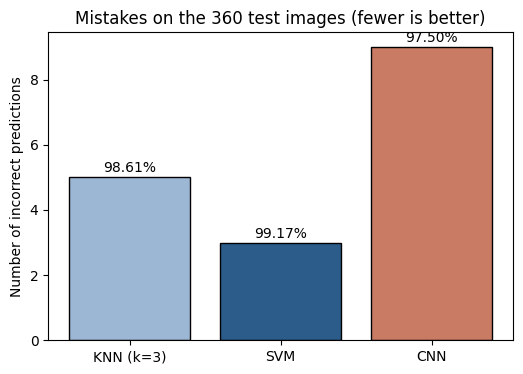

In [15]:
# Step 14: bar chart - number of mistakes per model
names = list(predictions.keys())
mistakes = [(Y_test != pred).sum() for pred in predictions.values()]
accuracies = [accuracy_score(Y_test, pred) for pred in predictions.values()]

plt.figure(figsize = (6, 4))
bars = plt.bar(names, mistakes, color = ["#9bb7d4", "#2b5c8a", "#c97b63"], edgecolor = "black")
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
             f"{acc:.2%}", ha = "center")                        # accuracy written above each bar
plt.title("Mistakes on the 360 test images (fewer is better)")
plt.ylabel("Number of incorrect predictions")
plt.savefig("model_comparison.png", bbox_inches = "tight")
plt.show()